# Анализ данных о Нобелевских лауреатах

## Введение

**Цель проекта** подготовить и проанализировать данные о Нобелевских лауреатах

Исходные данные представлены в формате JSON и содержат вложенные структуры с информацией о лауреатах и полученных ими премиях.

Проект состоит из двух основных этапов:

1. **Подготовка данных.** Для преобразования вложенных JSON-структур реализованы универсальные функции обработки на основе конфигурационных словарей. Они позволяют извлекать необходимые атрибуты, обрабатывать отсутствующие значения и применять дополнительные преобразования. Отдельные конфигурации предусмотрены для физических лиц, организаций и награждений.

2. **Исследовательский анализ данных (EDA).** Проведена проверка качества данных, рассчитаны описательные статистики, исследованы распределения награждений по странам, категориям, полу лауреатов и десятилетиям. Отдельно рассмотрены многократные лауреаты и денежные премии.

Обработка и анализ выполнены на Python без использования `pandas` и `numpy`. Вспомогательные функции вынесены в отдельные модули, а результаты исследования представлены в виде таблиц, графиков и аналитических выводов.

Подробное описание структуры проекта и назначения Python-модулей приведено в `README.md`.

## 1. Подготовка данных

### 1.1. Преобразование исходных данных

Исходный датасет содержит вложенные JSON-структуры с информацией о Нобелевских лауреатах и полученных ими премиях.

Для дальнейшего анализа необходимо преобразовать исходные записи в унифицированный список словарей, содержащих только интересующие атрибуты.

Основные особенности исходных данных:

- структура записей физических лиц и организаций различается;
- атрибуты расположены на разных уровнях вложенности;
- некоторые значения могут отсутствовать;
- отдельные атрибуты требуют преобразования типов или извлечения части значения.

Для решения этой задачи реализован **универсальный механизм обработки данных на основе конфигурационных словарей**.

Конфигурации `CONFIG_PERSON`, `CONFIG_ORG` и `CONFIG_PRIZE` определяют, какие атрибуты необходимо извлечь, где они находятся и требуется ли их дополнительное преобразование.

Универсальная функция `create_processor()` создаёт обработчик на основе соответствующей конфигурации.

### 1.2. Формирование итогового датасета

С помощью функции `main()` из модуля `core.py` исходный JSON-файл преобразуется в список словарей.

Для каждого лауреата определяется тип записи (`person` или `org`), после чего применяется соответствующая конфигурация обработки.

Полученный датасет содержит сведения о лауреатах и вложенный список их Нобелевских награждений. Корректность количества обработанных записей проверяется с помощью `assert`.

## Структура проекта

Для разделения логики обработки и анализа данных функциональность проекта вынесена в отдельные Python-модули.

| Файл | Назначение                                                                                                       |
|---|------------------------------------------------------------------------------------------------------------------|
| `core.py` | Загрузка исходного JSON-файла, определение типа лауреата и формирование итогового датасета.                      |
| `json_dict_processing.py` | Универсальные функции извлечения и преобразования данных из вложенных JSON-структур на основе конфигураций.      |
| `laureates_configs.py` | Конфигурации атрибутов физических лиц и организаций.                                                             |
| `prizes_configs.py` | Конфигурация атрибутов Нобелевских награждений.                                                                  |
| `data_preprocessing.py` | Проверка пропущенных значений, идентификаторов и корректности структуры данных. Нужен для первичного тех.анализа |
| `dataset_helpers.py` | Вспомогательные функции фильтрации, группировки и применения агрегаций.                                          |
| `aggregations.py` | Функции расчёта статистических показателей, частот, рейтингов и временных интервалов.                            |
| `atribute_manager.py` | Преобразование данных о награждениях и выявление многократных лауреатов.                                         |
| `final_project.ipynb` | Основной исследовательский анализ, визуализация результатов и выводы.                                            |

In [3]:
import core
import data_preprocessing as dp
import dataset_helpers as dh
import aggregations as ag
import matplotlib.pyplot as plt
import atribute_manager as at


In [4]:
laureates_data = core.main()

## Валидация кода
#### Проверим обработку вложенного словаря на тестовом примере


In [5]:
from json_dict_processing import process_dictionary_with_config
from prizes_configs import CONFIG_PRIZE

test_data = {
    "prizeAmount": 950000,
    "awardYear": "2015",
    "category": {
        "en": "Chemistry"
    },
    "prizeStatus": "received"
}

result = process_dictionary_with_config(test_data, CONFIG_PRIZE)

assert result["prize_amount"] == 950000
assert result["award_year"] == 2015
assert isinstance(result["award_year"], int)
assert result["category_en"] == "Chemistry"
assert result["prize_status"] == "received"
assert result["prize_amount_adjusted"] is None

##### Валидация структуры и корректности данных лауреатов Нобелевской премии

In [6]:
ids = set()

for laureate in laureates_data:
    assert isinstance(laureate, dict)
    assert laureate["type_"] in ("person", "org")
    assert laureate["id"] is not None
    assert isinstance(laureate["name"], str)
    assert isinstance(laureate["prizes_relevant"], list)

## EDA
#### Технический анализ собранных данных

Фильтрация на людей и организации

In [7]:
persons = dh.filter_data(laureates_data, "type_", lambda x: x == "person")
orgs = dh.filter_data(laureates_data, "type_", lambda x: x == "org")

Количество записей

In [8]:
count = len(laureates_data)
print("Количество записей:", count)
print("Количество записей людей-лауреатов:", len(persons))
print("Количество записей организаций-лауреатов:", len(orgs))

Количество записей: 1028
Количество записей людей-лауреатов: 1000
Количество записей организаций-лауреатов: 28


Наличие незаполненных значений в полях

In [9]:
#2. Есть ли незаполненные значения полей
print("Наличие незаполненных значений:", dp.find_none(laureates_data))
print("Наличие незаполненных значений у людей:", dp.find_none(persons))
print("Наличие незаполненных значений у организаций:", dp.find_none(orgs))

Наличие незаполненных значений: True
Наличие незаполненных значений у людей: True
Наличие незаполненных значений у организаций: True


Количество пропусков в каждом из полей. Какая доля пропусков

In [10]:
# Количество пропусков в каждом из полей. Какая доля пропусков
print("Сколько пропусков в каждом из полей")
print("Всего:")
print(dp.count_none(laureates_data))
print()
print("У людей:")
print(dp.count_none(persons))
print()
print("У организаций:", dp.count_none(orgs))
print()
print()


print("Доля этих пропусков")
print("Всего:")
print(dp.proportion_none(
    dp.count_none(laureates_data),
    dp.count_all(laureates_data))
    )
print()

print("У людей:")
print(dp.proportion_none(
    dp.count_none(persons),
    dp.count_all(persons))
    )
print()

print("У организаций:")
print(dp.proportion_none(
    dp.count_none(orgs),
    dp.count_all(orgs))
    )

Сколько пропусков в каждом из полей
Всего:
{'id': 0, 'name': 0, 'gender': 0, 'birth_year': 0, 'country_birth': 3, 'country_now': 7, 'prizes_relevant': 0, 'type_': 0, 'founded_year': 1, 'country_founded': 4}

У людей:
{'id': 0, 'name': 0, 'gender': 0, 'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'prizes_relevant': 0, 'type_': 0}

У организаций: {'id': 0, 'name': 0, 'founded_year': 1, 'country_founded': 4, 'country_now': 4, 'prizes_relevant': 0, 'type_': 0}


Доля этих пропусков
Всего:
{'id': 0.0, 'name': 0.0, 'gender': 0.0, 'birth_year': 0.0, 'country_birth': 0.003, 'country_now': 0.007, 'prizes_relevant': 0.0, 'type_': 0.0, 'founded_year': 0.036, 'country_founded': 0.143}

У людей:
{'id': 0.0, 'name': 0.0, 'gender': 0.0, 'birth_year': 0.0, 'country_birth': 0.003, 'country_now': 0.003, 'prizes_relevant': 0.0, 'type_': 0.0}

У организаций:
{'id': 0.0, 'name': 0.0, 'founded_year': 0.036, 'country_founded': 0.143, 'country_now': 0.143, 'prizes_relevant': 0.0, 'type_': 0.0}


Максимальные и минимальные значения поля id и относящиеся к ним года награждения

In [11]:
max_id = dp.max_value(laureates_data, "id", "award_year")
print("Для организаций и людей:")
print(max_id)
print("Для людей:")
print(dp.max_value(persons, "id", "award_year"))
print("Для организаций:")
print(dp.max_value(orgs, "id", "award_year"))
print()

print("Для организаций и людей:")
min_id = dp.min_value(laureates_data, "id", "award_year")
print(min_id)
print("Для людей:")
print(dp.min_value(persons, "id", "award_year"))
print("Для организаций:")
print(dp.min_value(orgs, "id", "award_year"))
print()

Для организаций и людей:
{'id': '1070', 'award_year': [2026]}
Для людей:
{'id': '1070', 'award_year': [2026]}
Для организаций:
{'id': '1043', 'award_year': [2024]}

Для организаций и людей:
{'id': '1', 'award_year': [1901]}
Для людей:
{'id': '1', 'award_year': [1901]}
Для организаций:
{'id': '467', 'award_year': [1904]}



Есть ли записи с повторяющимися id?

In [12]:
print("Для организаций и людей:")
print(dp.repeat_id(laureates_data))
if dp.repeat_id(laureates_data):
    print("Для людей:")
    print(dp.repeat_id(persons))
    print("Для организаций:")
    print(dp.repeat_id(orgs))
    print()

Для организаций и людей:
False


Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один?

In [13]:
diffs = dp.difference_couple_id(laureates_data)
print("Для организаций и людей:")
if len(diffs) > 0:
    print("Есть")
    print("Количество:", len(diffs))
    print("Пары:", diffs)
else:
    print("Нет")
print()

diffs_persons = dp.difference_couple_id(persons)
print("Для людей:")
if len(diffs_persons) > 0:
    print("Есть")
    print("Количество:", len(diffs_persons))
    print("Пары:", diffs_persons)
else:
    print("Нет")
print()

diffs_orgs = dp.difference_couple_id(orgs)
print("Для организаций:")
if len(diffs_orgs) > 0:
    print("Есть")
    print("Количество:", len(diffs_orgs))
    print("Пары:", diffs_orgs)
else:
    print("Нет")
print()

Для организаций и людей:
Есть
Количество: 24
Пары: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789), (858, 861), (896, 903), (949, 958), (1009, 1011)]

Для людей:
Есть
Количество: 48
Пары: [(6, 8), (93, 95), (169, 172), (255, 257), (466, 468), (468, 470), (476, 478), (481, 483), (502, 505), (507, 510), (514, 516), (520, 524), (524, 526), (526, 528), (536, 538), (541, 543), (546, 548), (549, 551), (560, 562), (563, 565), (567, 569), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (747, 749), (783, 786), (787, 789), (796, 798), (809, 811), (817, 819), (858, 861), (880, 882), (892, 894), (896, 903), (924, 926), (947, 949), (949, 958), (993, 995), (1009, 1011), (1018, 1021), (1042, 1044)]

Для организаций:
Есть
Количество: 25
Пары: [(467

### Выводы по первичному анализу данных

В ходе первичного анализа исследовано **1 028 записей о лауреатах Нобелевской премии**, из которых 1 000 относятся к физическим лицам и 28 у организаций.

**1. Анализ пропущенных значений**

Данные физических лиц достаточно полные: пропуски обнаружены только в атрибутах `country_birth` и `country_now` — по 3 записи в каждом (0,3%).

У организаций доля пропусков выше:
- `founded_year` — 1 запись (3,57%);
- `country_founded` — 4 записи (14,29%);
- `country_now` — 4 записи (14,29%).

Ключевые атрибуты(идентификатор, имя, тип лауреата и сведения о награждениях) не содержат пропусков.

**2. Анализ последовательности идентификаторов**

В ходе анализа выявлены разрывы между последовательными идентификаторами:
- Во всём датасете — 24 разрыва.
- Среди физических лиц — 48 разрывов.
- Среди организаций — 25 разрывов.

Увеличение числа разрывов при разделении на группы связано с тем, что идентификаторы людей и организаций входят в общую систему нумерации.

Также определены минимальные и максимальные идентификаторы и соответствующие годы награждения:

| Группа | Минимальный ID | Год награждения | Максимальный ID | Год награждения |
|---|---:|---:|---:|---:|
| Все лауреаты | 1 | 1901 | 1070 | 2026 |
| Физические лица | 1 | 1901 | 1070 | 2026 |
| Организации | 467 | 1904 | 1043 | 2024 |

Диапазон идентификаторов охватывает записи с награждениями с 1901 по 2026 год. Разрывы в нумерации
идентификаторов не обязательно свидетельствуют о потере записей.

**Общий вывод**

Датасет характеризуется высокой полнотой основных атрибутов и пригоден для дальнейшего анализа

## Анализ

## Топ-статистика по странам

### Топ-5 стран по количеству лауреатов

Определим пять стран с наибольшим количеством лауреатов. Для подсчёта используем атрибут `country_now`, обозначающий страну проживания на данный момент

[('USA', 306), ('United Kingdom', 96), ('Germany', 86), ('France', 66), ('Japan', 32)]


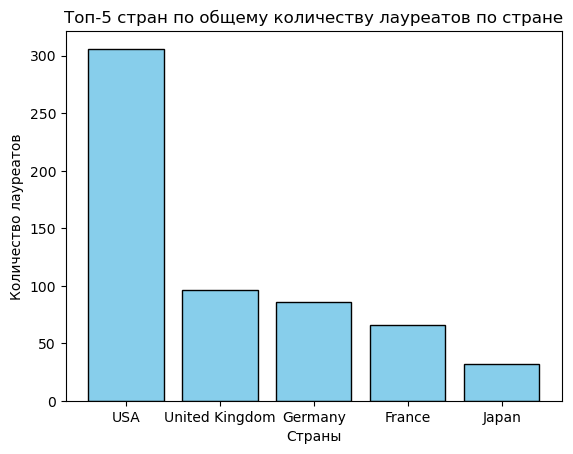

In [14]:
top = ag.top_n(laureates_data, 'country_now', 5)
print(top)

categories = []
values = []
for i in range(len(top)):
    categories.append(top[i][0])
    values.append(top[i][1])

plt.bar(categories, values, color='skyblue', edgecolor='black')
plt.title('Топ-5 стран по общему количеству лауреатов по стране')
plt.xlabel('Страны')
plt.ylabel('Количество лауреатов')
plt.show()


#### Рейтинг категорий

Определим наиболее распространённые категории Нобелевской премии среди лауреатов

[('Physiology or Medicine', 235), ('Physics', 231), ('Chemistry', 202), ('Peace', 144), ('Literature', 123), ('Economic Sciences', 101)]


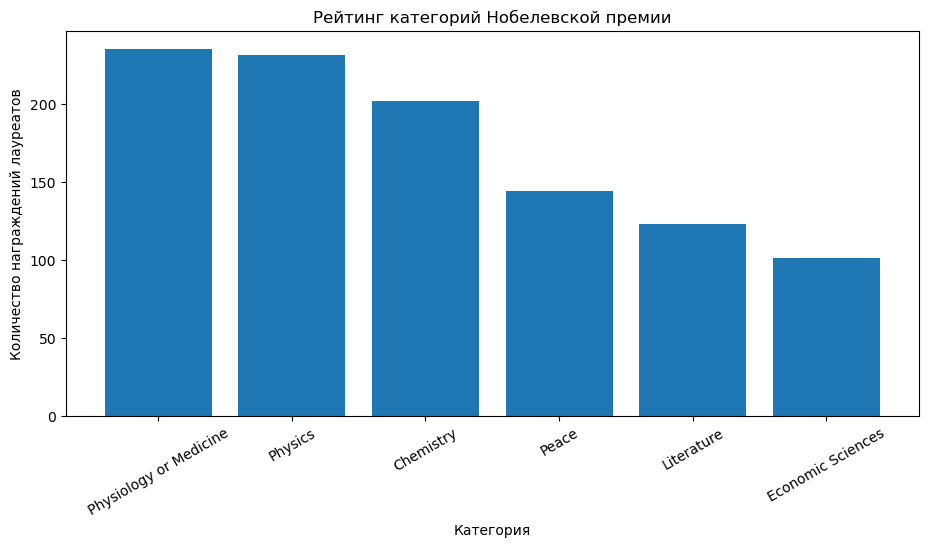

In [15]:
prizes_data = at.unpack_prizes(laureates_data)
top_science = ag.top_n(prizes_data, "category_en", 6)
print(top_science)
categories_science = [item[0] for item in top_science]
counts_science = [item[1] for item in top_science]

plt.figure(figsize=(11, 5))
plt.bar(categories_science, counts_science)

plt.title("Рейтинг категорий Нобелевской премии")
plt.xlabel("Категория")
plt.ylabel("Количество награждений лауреатов")
plt.xticks(rotation=30)
plt.show()

#### Топ стран по категориям Нобелевской премии

Определим для каждой категории Нобелевской премии страны, в которых ее чаще получают

In [40]:
groups = dh.group_data(prizes_data, ["category_en"])

for category, records in groups.items():
    top_5 = ag.top_n(records, "country_now", 5)
    print(f"\n{category[0]}:")

    for country, count in top_5:
        print(f"{country}: {count}")


Economic Sciences:
USA: 56
United Kingdom: 7
Canada: 5
France: 5
the Netherlands: 4

Physics:
USA: 72
Germany: 27
United Kingdom: 25
France: 13
Japan: 12

Chemistry:
USA: 60
United Kingdom: 27
Germany: 26
France: 12
Japan: 9

Literature:
France: 12
USA: 10
Sweden: 7
Poland: 7
Germany: 7

Peace:
USA: 26
France: 12
Switzerland: 11
United Kingdom: 7
Russia: 5

Physiology or Medicine:
USA: 85
United Kingdom: 25
Germany: 20
France: 12
Sweden: 8


### Динамика награждений Нобелевских лауреатов из топ-5 стран по десятилетиям

Исследуем изменение количества награждений в топ-5 стран по десятилетиям.

Для определения десятилетий используем функцию `add_interval()`. Она делит год награждения на 10 без остатка, умножает результат на 10 и записывает начало десятилетия в новый атрибут `award_year_interval`.

Например, для 2017 года функция определяет десятилетие как 2010-е.

Затем сгруппируем награждения по десятилетиям и странам.


1900-е годы:
USA 1
United Kingdom 3
Germany 8
France 9
Japan 0

1910-е годы:
USA 3
United Kingdom 2
Germany 6
France 6
Japan 0

1920-е годы:
USA 4
United Kingdom 7
Germany 10
France 8
Japan 0

1930-е годы:
USA 14
United Kingdom 10
Germany 8
France 3
Japan 0

1940-е годы:
USA 14
United Kingdom 4
Germany 3
France 1
Japan 1

1950-е годы:
USA 21
United Kingdom 10
Germany 6
France 4
Japan 0

1960-е годы:
USA 22
United Kingdom 7
Germany 7
France 8
Japan 2

1970-е годы:
USA 33
United Kingdom 14
Germany 8
France 4
Japan 2

1980-е годы:
USA 33
United Kingdom 5
Germany 11
France 4
Japan 2

1990-е годы:
USA 43
United Kingdom 6
Germany 4
France 2
Japan 1

2000-е годы:
USA 54
United Kingdom 10
Germany 6
France 4
Japan 8

2010-е годы:
USA 39
United Kingdom 11
Germany 4
France 5
Japan 11

2020-е годы:
USA 28
United Kingdom 8
Germany 5
France 8
Japan 5


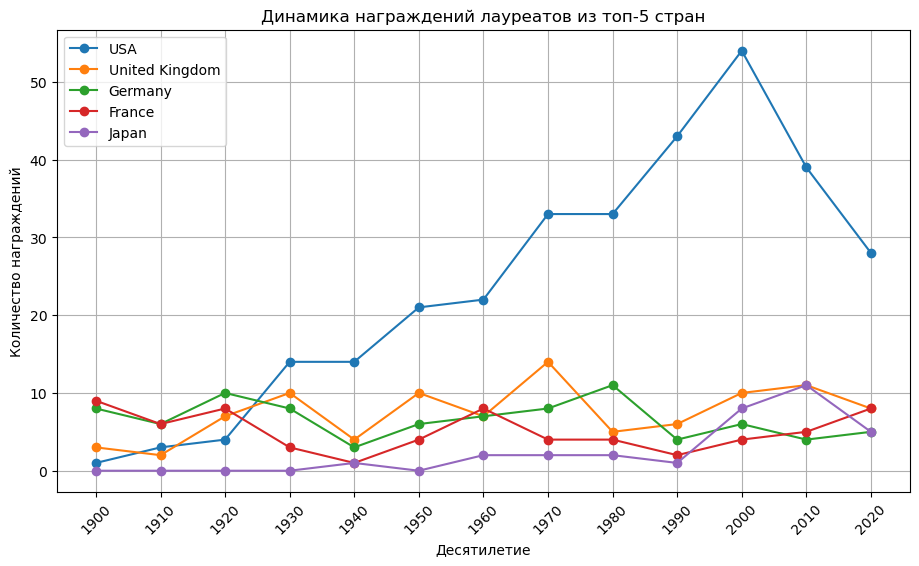

In [17]:
top_countries = categories
ag.add_interval(prizes_data, "award_year", 10)
groups = dh.group_data(
    prizes_data,
    ["award_year_interval", "country_now"]
)
result = {}

for key, records in groups.items():
    result[key] = len(records)

for decade in range(1900, 2030, 10):
    print(f"\n{decade}-е годы:")
    for country in top_countries:
        print(country, result.get((decade, country), 0))


decades = range(1900, 2030, 10)
plt.figure(figsize=(11, 6))
for country in top_countries:
    values = []
    for decade in decades:
        values.append(result.get((decade, country), 0))
    plt.plot(decades, values, marker="o", label=country)

plt.title("Динамика награждений лауреатов из топ-5 стран")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений")
plt.xticks(decades, rotation=45)
plt.legend()
plt.grid(True)
plt.show()

### Динамика награждений по научным категориям Нобелевской премии по десятилетиям


1900-е годы:
Physiology or Medicine 11
Physics 13
Chemistry 9
Peace 14
Literature 10
Economic Sciences 0

1910-е годы:
Physiology or Medicine 6
Physics 10
Chemistry 8
Peace 7
Literature 9
Economic Sciences 0

1920-е годы:
Physiology or Medicine 11
Physics 12
Chemistry 10
Peace 11
Literature 10
Economic Sciences 0

1930-е годы:
Physiology or Medicine 14
Physics 11
Chemistry 13
Peace 9
Literature 9
Economic Sciences 0

1940-е годы:
Physiology or Medicine 14
Physics 7
Chemistry 9
Peace 7
Literature 6
Economic Sciences 0

1950-е годы:
Physiology or Medicine 20
Physics 20
Chemistry 14
Peace 8
Literature 10
Economic Sciences 0

1960-е годы:
Physiology or Medicine 25
Physics 17
Chemistry 15
Peace 9
Literature 11
Economic Sciences 2

1970-е годы:
Physiology or Medicine 25
Physics 25
Chemistry 15
Peace 13
Literature 11
Economic Sciences 15

1980-е годы:
Physiology or Medicine 23
Physics 22
Chemistry 21
Peace 11
Literature 10
Economic Sciences 10

1990-е годы:
Physiology or Medicine 20
Physics 

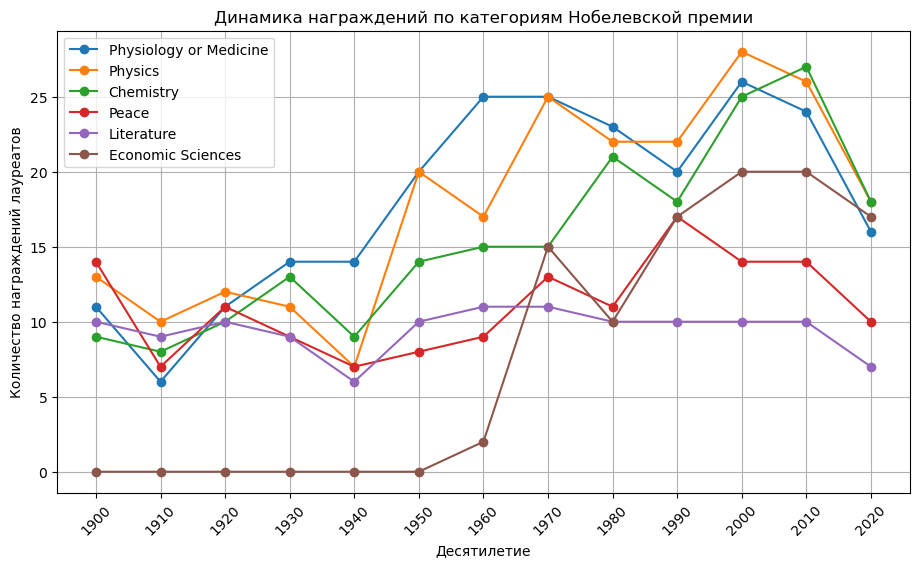

In [18]:
ag.add_interval(prizes_data, "award_year", 10)

groups = dh.group_data(
    prizes_data,
    ["award_year_interval", "category_en"]
)

result = {}
for key, records in groups.items():
    result[key] = len(records)

decades = range(1900, 2030, 10)
for decade in decades:
    print(f"\n{decade}-е годы:")
    for category in categories_science:
        print(category, result.get((decade, category), 0))

plt.figure(figsize=(11, 6))
for category in categories_science:
    values = []
    for decade in decades:
        values.append(result.get((decade, category), 0))
    plt.plot(decades, values, marker="o", label=category)

plt.title("Динамика награждений по категориям Нобелевской премии")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений лауреатов")
plt.xticks(decades, rotation=45)
plt.legend()
plt.grid(True)
plt.show()


### Сравнение денежных премий Нобелевских лауреатов по странам
Рассчитаем средний, медианный, минимальный и максимальный размеры денежных премий с поправкой на инфляцию для каждой страны. Это позволит сравнить распределение размеров награждений между рассматриваемыми группами лауреатов.

In [19]:
groups = dh.group_data(prizes_data, ["country_now"])

result = {}

for country, records in groups.items():
    result[country[0]] = dh.apply_aggregations(
        records,
        "prize_amount_adjusted",
        ["mean", "median", "min", "max"]
    )

for country, stats in result.items():
    print(country, stats)

USA {'mean': 8675513.601941748, 'median': 10573021, 'min': 3006134, 'max': 15547541}
Denmark {'mean': 5799353, 'median': 4631210.5, 'min': 3028106, 'max': 12105174}
Israel {'mean': 13260090.166666666, 'median': 13596300.5, 'min': 10578918, 'max': 15218228}
Lithuania {'mean': 3824442.3333333335, 'median': 3896009, 'min': 3654081, 'max': 3923237}
None {'mean': 11173326.285714285, 'median': 11000000, 'min': 10573021, 'max': 12361835}
Pakistan {'mean': 6357761.666666667, 'median': 4698151, 'min': 3778486, 'max': 10596648}
India {'mean': 9551369.111111112, 'median': 10191492, 'min': 3859767, 'max': 13857393}
Ethiopia {'mean': 11178104, 'median': 11178104, 'min': 11178104, 'max': 11178104}
Germany {'mean': 7040862.383720931, 'median': 5874628.0, 'min': 3006134, 'max': 15547541}
Argentina {'mean': 4583841, 'median': 4234048.5, 'min': 3654081, 'max': 6213186}
Egypt {'mean': 8721543.166666666, 'median': 8785446.5, 'min': 3576149, 'max': 14809494}
Japan {'mean': 10463129.53125, 'median': 1100000

## Выводы

- Наибольшее количество Нобелевских лауреатов приходится на США (**306 человек**). Далее следуют Великобритания (96), Германия (86), Франция (66) и Япония (32).
- США лидируют по количеству награждений в большинстве категорий, однако в литературе первое место занимает Франция 12 награждений против 10 у США.
- В начале XX века среди рассматриваемых стран выделялись Германия и Франция, тогда как со второй половины XX века заметно усилилось лидерство США.
- Наибольшее количество награждений за рассматриваемый период приходится на **физиологию или медицину (235)**, физику (231) и химию (202). Эти три категории заметно опережают остальные.
 - По абсолютному количеству награждений лидирует **физиология или медицина**, однако для более корректного сравнения категорий следует учитывать количество лет, в течение которых присуждалась каждая премия.

## Многократные лауреаты
#### Лауреаты, получившие больше одной Нобелевской премии

Выделим лауреатов, получивших Нобелевскую премию более одного раза. Определим количество награждений, годы их получения и категории премий.

In [20]:
multiple_laureates = at.get_multiple_laureates(prizes_data)

for laureate in multiple_laureates:
    print(f"\n{laureate['name']} — {laureate['prizes_count']} премии")

    for prize in laureate["prizes"]:
        print(
            prize["award_year"],
            prize["category_en"]
        )


Frederick Sanger — 2 премии
1958 Chemistry
1980 Chemistry

International Committee of the Red Cross — 3 премии
1917 Peace
1944 Peace
1963 Peace

John Bardeen — 2 премии
1956 Physics
1972 Physics

K. Barry Sharpless — 2 премии
2001 Chemistry
2022 Chemistry

Linus Pauling — 2 премии
1954 Chemistry
1962 Peace

Marie Curie — 2 премии
1903 Physics
1911 Chemistry

Office of the United Nations High Commissioner for Refugees — 2 премии
1954 Peace
1981 Peace


### Совпадают ли категории премии у людей, получивших премию не один раз

In [21]:
for laureate in multiple_laureates:
    categories = ag.count(laureate["prizes"], "category_en")


    print(f"\n{laureate['name']}")
    print(f"Количество премий: {laureate['prizes_count']}")
    print(f"Совпадают ли категории первых двух премий: "
          f"{'Да' if laureate['same_category'] else 'Нет'}")
    print(f"Категории: {', '.join(categories)}")
    print(f"Интервал между первой и второй премиями: {laureate['years_between']} лет")
    print()


Frederick Sanger
Количество премий: 2
Совпадают ли категории первых двух премий: Да
Категории: Chemistry
Интервал между первой и второй премиями: 22 лет


International Committee of the Red Cross
Количество премий: 3
Совпадают ли категории первых двух премий: Да
Категории: Peace
Интервал между первой и второй премиями: 27 лет


John Bardeen
Количество премий: 2
Совпадают ли категории первых двух премий: Да
Категории: Physics
Интервал между первой и второй премиями: 16 лет


K. Barry Sharpless
Количество премий: 2
Совпадают ли категории первых двух премий: Да
Категории: Chemistry
Интервал между первой и второй премиями: 21 лет


Linus Pauling
Количество премий: 2
Совпадают ли категории первых двух премий: Нет
Категории: Chemistry, Peace
Интервал между первой и второй премиями: 8 лет


Marie Curie
Количество премий: 2
Совпадают ли категории первых двух премий: Нет
Категории: Physics, Chemistry
Интервал между первой и второй премиями: 8 лет


Office of the United Nations High Commissione

### Средний, медианный и экстремальные интервалы между первой и второй Нобелевскими премиями

In [22]:
stats = dh.apply_aggregations(
    multiple_laureates,
    "years_between",
    ["mean", "median", "min", "max"]
)

print(f"Среднее время между премиями:   {round(stats['mean'], 2)} лет")
print(f"Медианное время между премиями: {stats['median']} лет")
print(f"Минимальный интервал:           {stats['min']} лет")
print(f"Максимальный интервал:          {stats['max']} лет")

Среднее время между премиями:   18.43 лет
Медианное время между премиями: 21 лет
Минимальный интервал:           8 лет
Максимальный интервал:          27 лет


### Сравнительный анализ интервалов между награждениями людей и организаций

In [23]:
groups = dh.group_data(multiple_laureates, ["type_"])

for laureate_type, records in groups.items():
    stats = dh.apply_aggregations(
        records, "years_between", ["mean", "median", "min", "max"]
    )

    print(f"\n{'Люди' if laureate_type[0] == 'person' else 'Организации'}")
    print(f"Количество многократных лауреатов: {len(records)}")
    print(f"Средний интервал:                {stats['mean']} лет")
    print(f"Медианный интервал:              {stats['median']} лет")
    print(f"Минимальный интервал:            {stats['min']} лет")
    print(f"Максимальный интервал:           {stats['max']} лет")


Люди
Количество многократных лауреатов: 5
Средний интервал:                15 лет
Медианный интервал:              16 лет
Минимальный интервал:            8 лет
Максимальный интервал:           22 лет

Организации
Количество многократных лауреатов: 2
Средний интервал:                27 лет
Медианный интервал:              27.0 лет
Минимальный интервал:            27 лет
Максимальный интервал:           27 лет


## Выводы

### Анализ многократных лауреатов

- В исследуемом наборе данных выявлено **7 многократных лауреатов**: 5 физических лиц и 2 организации.
- У 5 из 7 лауреатов категории первой и второй премий совпадают.
- Исключениями являются Мария Кюри, получившая премии по физике и химии, и Лайнус Полинг, награждённый по химии и премией мира.
- Средний интервал между первым и вторым награждением составляет **18,43 года**, медианный 21 год.
- Минимальный интервал равен 8 годам, максимальный 27 годам.
- У физических лиц средний интервал составляет 15 лет, тогда как у организаций 27 лет.

## Гендерное распределение
### Динамика награждений Нобелевской премией у женщин по десятилетиям

In [24]:
women = dh.filter_data(persons, "gender", lambda x: x == "female")

women_prizes = at.unpack_prizes(women)

ag.add_interval(women_prizes, "award_year", 10)

decade_counts = ag.count(women_prizes, "award_year_interval")

for decade in range(1900, 2030, 10):
    print(f"{decade}-е: {decade_counts.get(decade, 0)}")

1900-е: 3
1910-е: 1
1920-е: 2
1930-е: 3
1940-е: 3
1950-е: 0
1960-е: 3
1970-е: 4
1980-е: 4
1990-е: 7
2000-е: 11
2010-е: 13
2020-е: 16


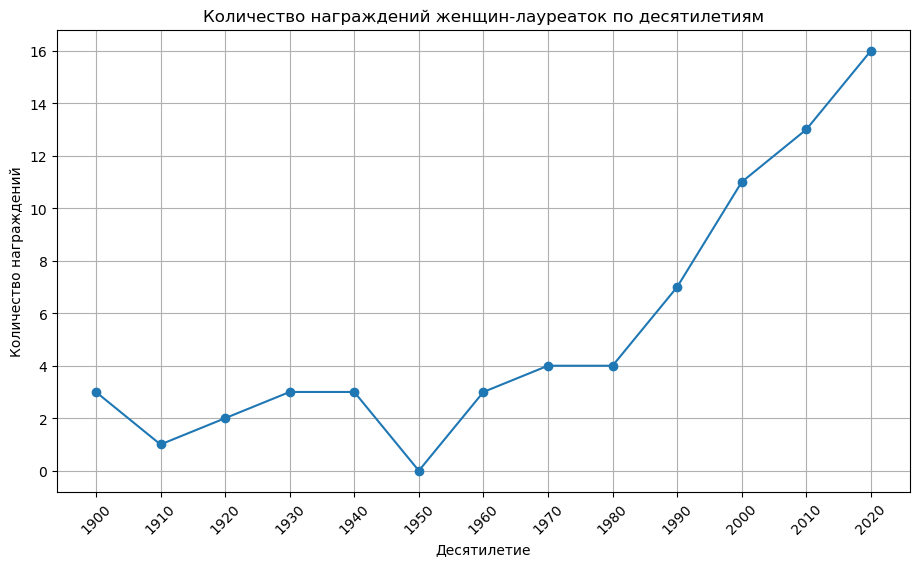

In [25]:
decades = list(range(1900, 2030, 10))
values = [decade_counts.get(decade, 0) for decade in decades]

plt.figure(figsize=(11, 6))
plt.plot(decades, values, marker="o")
plt.title("Количество награждений женщин-лауреаток по десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений")
plt.xticks(decades, rotation=45)
plt.grid(True)
plt.show()

### Распределение лауреаток по категориям Нобелевской премии
Определим количество уникальных женщин-лауреатов в каждой категории за весь рассматриваемый период. Для исключения повторных награждений одного человека в одной категории сгруппируем записи по идентификатору лауреата и категории премии.

In [26]:
groups = dh.group_data(women_prizes, ["id", "category_en"])
unique_women = [records[0] for records in groups.values()]
top_categories = ag.top_n(unique_women, "category_en", 6)

for category, count in top_categories:
    print(f"{category}: {count}")

Peace: 21
Literature: 19
Physiology or Medicine: 14
Chemistry: 8
Physics: 5
Economic Sciences: 3


### Динамика для каждой категорий Нобелевской премии у женщин по десятилетиям

In [27]:
groups = dh.group_data(
    women_prizes,
    ["award_year_interval", "category_en"]
)

result = {}

for key, records in groups.items():
    result[key] = len(records)

for decade in range(1900, 2030, 10):
    print(f"\n{decade}-е годы:")

    for category, _ in top_categories:
        print(f"{category}: {result.get((decade, category), 0)}")


1900-е годы:
Peace: 1
Literature: 1
Physiology or Medicine: 0
Chemistry: 0
Physics: 1
Economic Sciences: 0

1910-е годы:
Peace: 0
Literature: 0
Physiology or Medicine: 0
Chemistry: 1
Physics: 0
Economic Sciences: 0

1920-е годы:
Peace: 0
Literature: 2
Physiology or Medicine: 0
Chemistry: 0
Physics: 0
Economic Sciences: 0

1930-е годы:
Peace: 1
Literature: 1
Physiology or Medicine: 0
Chemistry: 1
Physics: 0
Economic Sciences: 0

1940-е годы:
Peace: 1
Literature: 1
Physiology or Medicine: 1
Chemistry: 0
Physics: 0
Economic Sciences: 0

1950-е годы:
Peace: 0
Literature: 0
Physiology or Medicine: 0
Chemistry: 0
Physics: 0
Economic Sciences: 0

1960-е годы:
Peace: 0
Literature: 1
Physiology or Medicine: 0
Chemistry: 1
Physics: 1
Economic Sciences: 0

1970-е годы:
Peace: 3
Literature: 0
Physiology or Medicine: 1
Chemistry: 0
Physics: 0
Economic Sciences: 0

1980-е годы:
Peace: 1
Literature: 0
Physiology or Medicine: 3
Chemistry: 0
Physics: 0
Economic Sciences: 0

1990-е годы:
Peace: 3
Liter

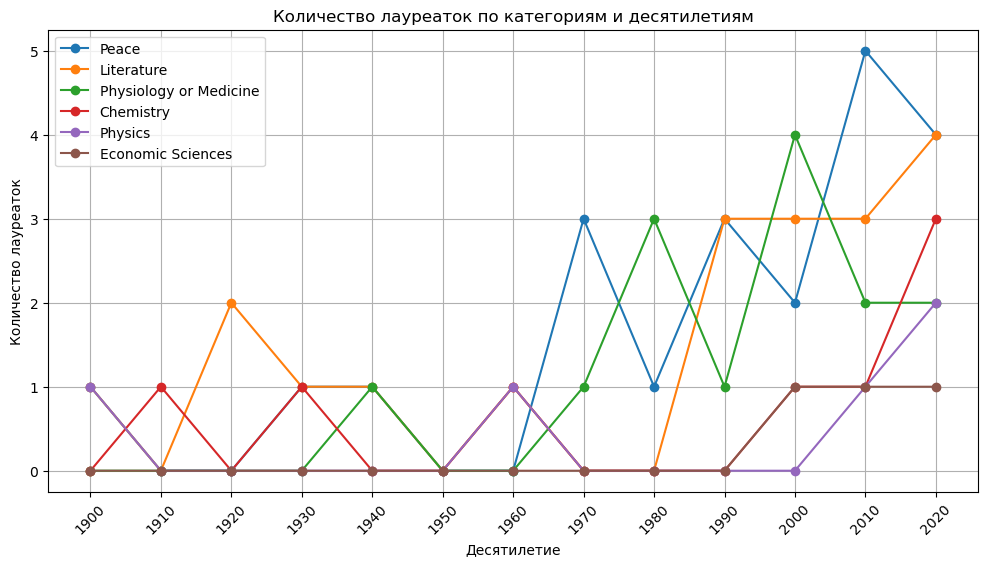

In [28]:
decades = list(range(1900, 2030, 10))
plt.figure(figsize=(12, 6))
for category, _ in top_categories:
    values = []

    for decade in decades:
        values.append(result.get((decade, category), 0))

    plt.plot(decades, values, marker="o", label=category)

plt.title("Количество лауреаток по категориям и десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений")
plt.xticks(decades, rotation=45)
plt.legend()
plt.grid(True)
plt.show()

### Сравнение тотального количества премий в категориях в ранний и современный периоды у женщин

In [29]:
for period, decades in [
    ("1900–1929",range(1900, 1930, 10)),
    ("2000–2029", range(2000, 2030, 10))
]:
    print(f"\n{period}:")

    for category, _ in top_categories:
        count = sum(result.get((decade, category), 0) for decade in decades)
        print(f"{category}: {count}")


1900–1929:
Peace: 1
Literature: 3
Physiology or Medicine: 0
Chemistry: 1
Physics: 1
Economic Sciences: 0

1999–2029:
Peace: 11
Literature: 10
Physiology or Medicine: 8
Chemistry: 5
Physics: 3
Economic Sciences: 3


### Динамика количества награждений мужчин-лауреатов по десятилетиям

In [30]:
men = dh.filter_data(persons, "gender", lambda x: x == "male")

men_prizes = at.unpack_prizes(men)

ag.add_interval(men_prizes, "award_year", 10)

men_decade_counts = ag.count(men_prizes, "award_year_interval")

for decade in range(1900, 2030, 10):
    print(f"{decade}-е: {men_decade_counts.get(decade, 0)}")

1900-е: 53
1910-е: 37
1920-е: 52
1930-е: 52
1940-е: 37
1950-е: 71
1960-е: 72
1970-е: 99
1980-е: 90
1990-е: 94
2000-е: 108
2010-е: 104
2020-е: 66


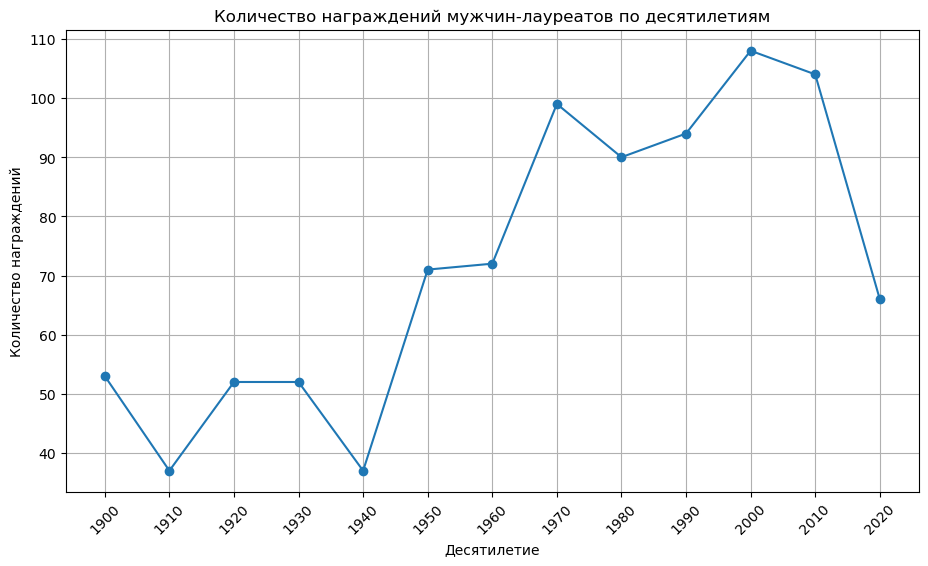

In [31]:
decades = list(range(1900, 2030, 10))
values = [men_decade_counts.get(decade, 0) for decade in decades]

plt.figure(figsize=(11, 6))
plt.plot(decades, values, marker="o")
plt.title("Количество награждений мужчин-лауреатов по десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений")
plt.xticks(decades, rotation=45)
plt.grid(True)
plt.show()

### Распределение мужчин-лауреатов по категориям Нобелевской премии

In [32]:
groups = dh.group_data(men_prizes, ["id", "category_en"])
unique_men = [records[0] for records in groups.values()]
top_men_categories = ag.top_n(unique_men, "category_en", 6)

for category, count in top_men_categories:
    print(f"{category}: {count}")

Physics: 225
Physiology or Medicine: 221
Chemistry: 192
Literature: 104
Economic Sciences: 98
Peace: 92


### Динамика награждений мужчин по категориям и десятилетиям

In [33]:
men_groups = dh.group_data(
    men_prizes,
    ["award_year_interval", "category_en"]
)

men_result = {}

for key, records in men_groups.items():
    men_result[key] = len(records)

for decade in range(1900, 2030, 10):
    print(f"\n{decade}-е годы:")

    for category, count in top_men_categories:
        print(f"{category}: {men_result.get((decade, category), 0)}")


1900-е годы:
Physics: 12
Physiology or Medicine: 11
Chemistry: 9
Literature: 9
Economic Sciences: 0
Peace: 12

1910-е годы:
Physics: 10
Physiology or Medicine: 6
Chemistry: 7
Literature: 9
Economic Sciences: 0
Peace: 5

1920-е годы:
Physics: 12
Physiology or Medicine: 11
Chemistry: 10
Literature: 8
Economic Sciences: 0
Peace: 11

1930-е годы:
Physics: 11
Physiology or Medicine: 14
Chemistry: 12
Literature: 8
Economic Sciences: 0
Peace: 7

1940-е годы:
Physics: 7
Physiology or Medicine: 13
Chemistry: 9
Literature: 5
Economic Sciences: 0
Peace: 3

1950-е годы:
Physics: 20
Physiology or Medicine: 20
Chemistry: 14
Literature: 10
Economic Sciences: 0
Peace: 7

1960-е годы:
Physics: 16
Physiology or Medicine: 25
Chemistry: 14
Literature: 10
Economic Sciences: 2
Peace: 5

1970-е годы:
Physics: 25
Physiology or Medicine: 24
Chemistry: 15
Literature: 11
Economic Sciences: 15
Peace: 9

1980-е годы:
Physics: 22
Physiology or Medicine: 20
Chemistry: 21
Literature: 10
Economic Sciences: 10
Peace: 

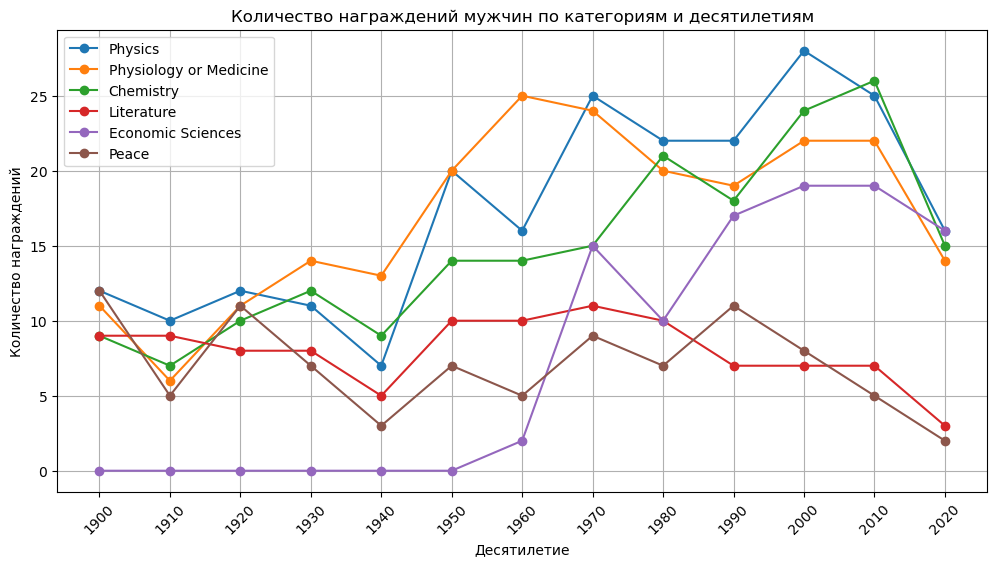

In [34]:
plt.figure(figsize=(12, 6))

for category, _ in top_men_categories:
    values = []

    for decade in decades:
        values.append(men_result.get((decade, category), 0))

    plt.plot(decades, values, marker="o", label=category)

plt.title("Количество награждений мужчин по категориям и десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений")
plt.xticks(decades, rotation=45)
plt.legend()
plt.grid(True)
plt.show()

### Сравнение категорий Нобелевской премии среди мужчин в ранний и современный периоды

In [35]:
for period, decades in [
    ("1900–1929", range(1900, 1930, 10)),
    ("2000–2029", range(2000, 2030, 10))
]:
    print(f"\n{period}:")

    for category, _ in top_men_categories:
        count = sum(men_result.get((decade, category), 0) for decade in decades)
        print(f"{category}: {count}")


1900–1929:
Physics: 34
Physiology or Medicine: 28
Chemistry: 26
Literature: 26
Economic Sciences: 0
Peace: 28

2000–2029:
Physics: 69
Physiology or Medicine: 58
Chemistry: 65
Literature: 17
Economic Sciences: 54
Peace: 15


### Сравнение количества награждений мужчин и женщин по десятилетиям

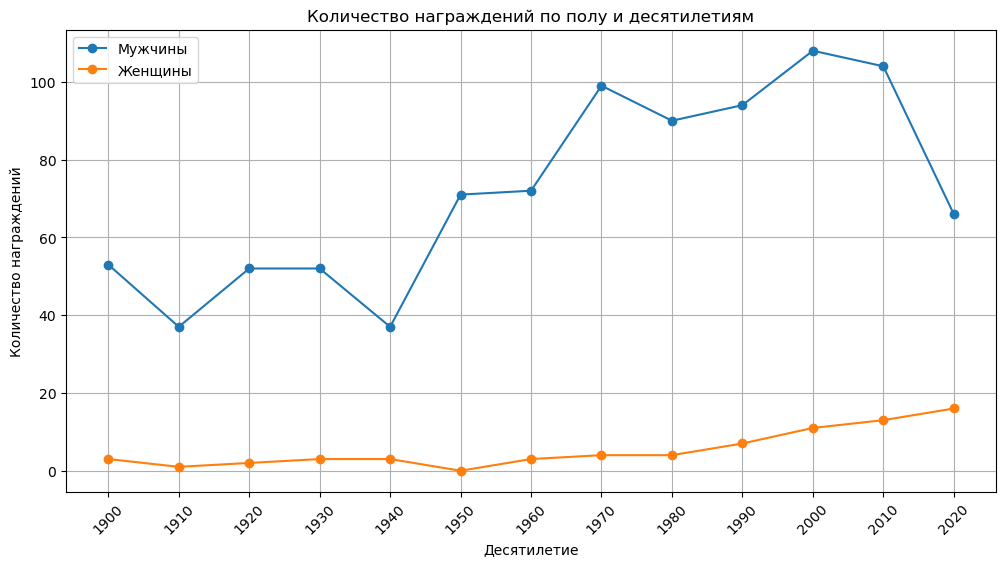

In [36]:
decades = list(range(1900, 2030, 10))

men_values = [men_decade_counts.get(decade, 0) for decade in decades]
women_values = [decade_counts.get(decade, 0) for decade in decades]

plt.figure(figsize=(12, 6))

plt.plot(decades, men_values, marker="o", label="Мужчины")
plt.plot(decades, women_values, marker="o", label="Женщины")

plt.title("Количество награждений по полу и десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Количество награждений")
plt.xticks(decades, rotation=45)
plt.legend()
plt.grid(True)
plt.show()

### Изменение доли награждений женщин среди всех награждений физических лиц по десятилетиям.

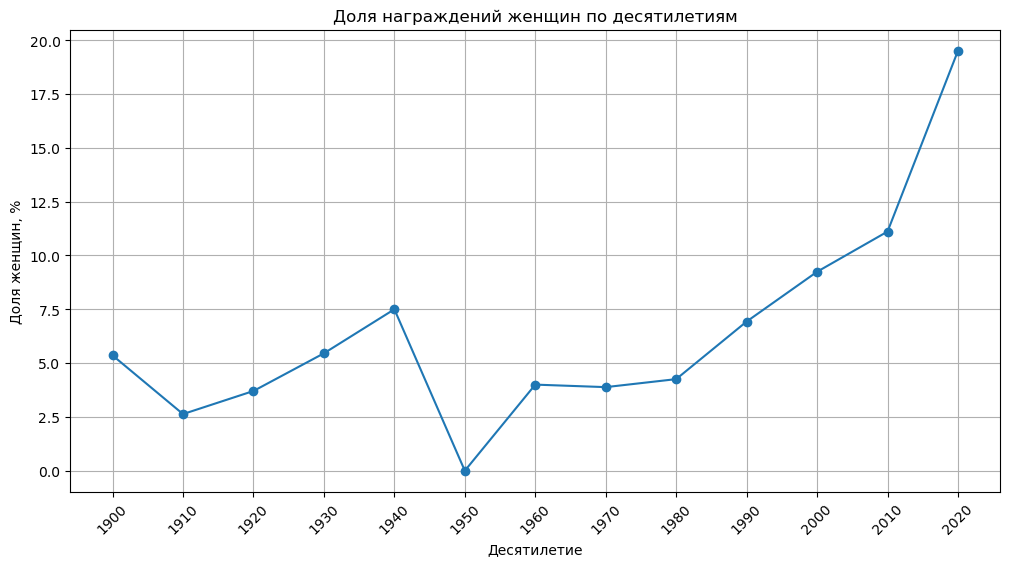

In [37]:
women_share = []

for decade in decades:
    men_count = men_decade_counts.get(decade, 0)
    women_count = decade_counts.get(decade, 0)

    total = men_count + women_count
    women_share.append(women_count / total * 100)

plt.figure(figsize=(12, 6))
plt.plot(decades, women_share, marker="o")

plt.title("Доля награждений женщин по десятилетиям")
plt.xlabel("Десятилетие")
plt.ylabel("Доля женщин, %")
plt.xticks(decades, rotation=45)
plt.grid(True)
plt.show()

### Доля награждений женщин по категориям Нобелевской премии

In [38]:
men_counts = ag.count(men_prizes, "category_en")
women_counts = ag.count(women_prizes, "category_en")

categories = list(men_counts.keys())

for category in categories:
    men_count = men_counts[category]
    women_count = women_counts.get(category, 0)

    total = men_count + women_count
    share = women_count / total * 100

    print(f"{category}: {share:.1f}% женщин")

Economic Sciences: 3.0% женщин
Physics: 2.2% женщин
Chemistry: 4.0% женщин
Literature: 15.4% женщин
Peace: 18.6% женщин
Physiology or Medicine: 6.0% женщин


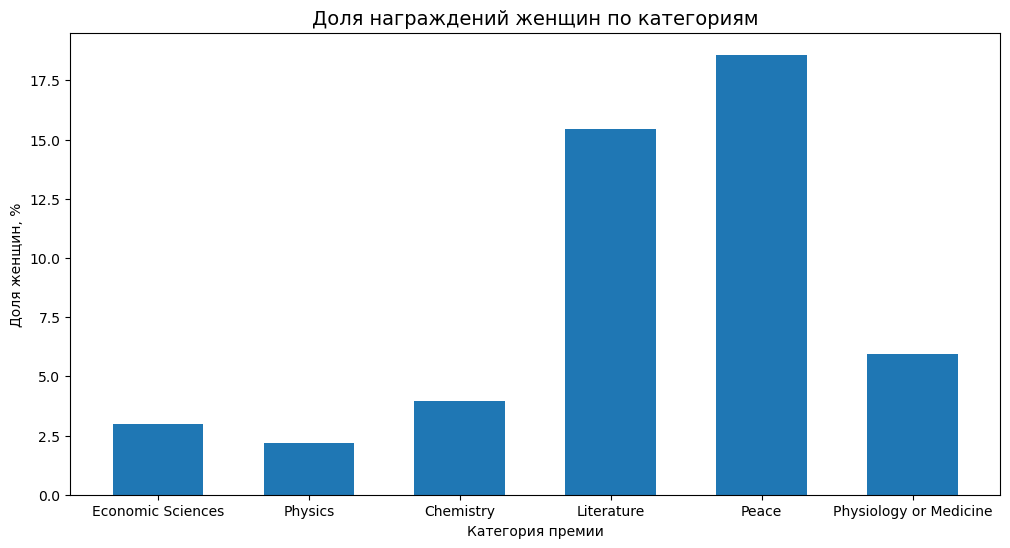

In [39]:
shares = []

for category in categories:
    men_count = men_counts[category]
    women_count = women_counts.get(category, 0)

    shares.append(women_count / (men_count + women_count) * 100)

plt.figure(figsize=(12, 6))

bars = plt.bar(categories, shares, width=0.6)
plt.title("Доля награждений женщин по категориям", fontsize=14)
plt.xlabel("Категория премии")
plt.ylabel("Доля женщин, %")
plt.show()

## Выводы
### Гендерное распределение Нобелевских награждений

- Среди получателей Нобелевской премии наблюдается значительное преобладание мужчин.
- Количество награждений женщин постепенно увеличивалось: с 3 в 1900-е годы до 13 в 2010-е и 16 в 2020–2026 годах.
- Наибольшая представленность женщин наблюдается в категориях премии мира (18,6%) и литературы (15,4%).
- Наименьшая доля награждений женщин приходится на физику (2,2%), экономические науки (3,0%) и химию (4,0%).
- В 1900–1929 годах среди женщин лидировала литература (3 награждения), тогда как в современный период с 2000 года наибольшее количество награждений женщин приходится на премию мира (11).
- Несмотря на увеличение представленности женщин, гендерный дисбаланс сохраняется, особенно в естественно-научных категориях.